<a href="https://colab.research.google.com/github/govrahul/aipi510_week12/blob/main/water_potability_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
!pip install -q mlflow

In [21]:
import copy, json, os, warnings

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import yaml
from mlflow.models import infer_signature
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 510
np.random.seed(SEED)

In [22]:
RAW_URL = "https://raw.githubusercontent.com/govrahul/aipi510_week12/main/Data/water_potability.csv"

# Columns removed during cleaning: lab-only tests, plus turbidity (only roughly home-testable)
DROP_COLUMNS = ["Organic_carbon", "Trihalomethanes", "Turbidity"]

CONFIG = {
    "data": {
        "source_url": RAW_URL,
        "target": "potability",
        # solids stays in the cleaned CSV but is left out of the model by default
        # (it contradicts conductivity, see Section 4); one experiment adds it back
        "features": ["ph", "hardness", "chloramines", "sulfate", "conductivity"],
    },
    "split": {"test_size": 0.2, "val_size": 0.1, "stratify": True, "random_state": SEED},
    "preprocessing": {"imputer_strategy": "median", "add_indicator": False},
    "model": {
        "n_estimators": 200,
        "max_depth": 10,
        "min_samples_leaf": 5,
        "class_weight": "balanced",
        "random_state": SEED,
        "n_jobs": -1,
    },
    "mlflow": {"tracking_uri": "sqlite:///mlflow.db", "experiment_name": "water-potability"},
}

In [23]:
raw = pd.read_csv(CONFIG["data"]["source_url"])
print("Shape:", raw.shape)
display(raw.head())
display(raw.describe().T.round(2))

Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.08,1.59,0.00,6.09,7.04,8.06,14.00
Hardness,3276.0,196.37,32.88,47.43,176.85,196.97,216.67,323.12
Solids,3276.0,22014.09,8768.57,320.94,15666.69,20927.83,27332.76,61227.20
Chloramines,3276.0,7.12,1.58,0.35,6.13,7.13,8.11,13.13
Sulfate,2495.0,333.78,41.42,129.00,307.70,333.07,359.95,481.03
Conductivity,3276.0,426.21,80.82,181.48,365.73,421.88,481.79,753.34
Organic_carbon,3276.0,14.28,3.31,2.20,12.07,14.22,16.56,28.30
Trihalomethanes,3114.0,66.40,16.18,0.74,55.84,66.62,77.34,124.00
Turbidity,3276.0,3.97,0.78,1.45,3.44,3.96,4.50,6.74
Potability,3276.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00


In [24]:
EPA_LIMITS = {
    # column: (lower limit, upper limit, type of standard)
    "ph":              (6.5, 8.5,  "secondary (taste/odor)"),
    "Solids":          (None, 500, "secondary (taste/odor)"),
    "Chloramines":     (None, 4.0, "enforceable health limit"),
    "Sulfate":         (None, 250, "secondary (taste/odor)"),
    "Trihalomethanes": (None, 80,  "enforceable health limit"),
    "Turbidity":       (None, 1.0, "treatment technique"),
}

rows = []
for col, (lo, hi, kind) in EPA_LIMITS.items():
    s = raw[col].dropna()
    outside = pd.Series(False, index=s.index)
    if lo is not None:
        outside |= s < lo
    if hi is not None:
        outside |= s > hi
    potable = raw.loc[s.index, "Potability"] == 1
    rows.append({
        "feature": col,
        "EPA limit": f"{lo}-{hi}" if lo is not None else f"<= {hi}",
        "type": kind,
        "% rows outside": round(outside.mean() * 100, 1),
        "% 'potable' rows outside": round(outside[potable].mean() * 100, 1),
    })
display(pd.DataFrame(rows))

,feature,EPA limit,type,% rows outside,% 'potable' rows outside
0,ph,6.5-8.5,secondary (taste/odor),52.3,47.0
1,Solids,<= 500,secondary (taste/odor),100.0,100.0
2,Chloramines,<= 4.0,enforceable health limit,97.3,97.2
3,Sulfate,<= 250,secondary (taste/odor),97.7,95.9
4,Trihalomethanes,<= 80,enforceable health limit,19.3,19.5
5,Turbidity,<= 1.0,treatment technique,100.0,100.0


In [25]:
ratio = raw["Solids"] / raw["Conductivity"]
print(f"Median solids/conductivity ratio: {ratio.median():.1f}   (real water: about 0.6)")
print(f"Correlation solids vs conductivity: {raw['Solids'].corr(raw['Conductivity']):.3f}   (real water: close to 1)")
print(f"'Potable' rows with TDS above 1,000 mg/L: {(raw.loc[raw['Potability'] == 1, 'Solids'] > 1000).mean():.0%}")

Median solids/conductivity ratio: 50.3   (real water: about 0.6)
Correlation solids vs conductivity: 0.014   (real water: close to 1)
'Potable' rows with TDS above 1,000 mg/L: 100%


## 5. Clean the data
- Drop lab-only columns and turbidity
- Rename to snake_case (these names become the API's JSON keys)
- Remove duplicate rows
- Set physically impossible values to missing: pH of exactly 0 or 14, or any negative concentration

Missing values are **not** filled here. The imputer inside the model pipeline fills them, fit on training data only.

In [26]:
df = raw.drop(columns=DROP_COLUMNS)
df.columns = (df.columns.str.strip().str.lower()
                .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
TARGET = CONFIG["data"]["target"]

n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {n_before - len(df)}")

bad_ph = (df["ph"] <= 0) | (df["ph"] >= 14)
print(f"Impossible pH values set to missing: {int(bad_ph.sum())}")
df.loc[bad_ph, "ph"] = np.nan

for col in df.columns.drop(TARGET):
    neg = df[col] < 0
    if neg.any():
        print(f"Negative {col} values set to missing: {int(neg.sum())}")
        df.loc[neg, col] = np.nan

assert set(df[TARGET].unique()) <= {0, 1}
df[TARGET] = df[TARGET].astype(int)

print("\nColumns:", list(df.columns))
print("Shape:", df.shape)
display((df.isna().mean() * 100).round(1).to_frame("% missing"))

counts = df[TARGET].value_counts().sort_index()
print("Class balance (0 = not potable, 1 = potable):")
display(pd.DataFrame({"count": counts, "share": (counts / counts.sum()).round(3)}))

Duplicates removed: 0
Impossible pH values set to missing: 1

Columns: ['ph', 'hardness', 'solids', 'chloramines', 'sulfate', 'conductivity', 'potability']
Shape: (3276, 7)


,% missing
ph,15.0
hardness,0.0
solids,0.0
chloramines,0.0
sulfate,23.8
conductivity,0.0
potability,0.0


Class balance (0 = not potable, 1 = potable):


,count,share
potability,,
0,1998,0.61
1,1278,0.39


In [27]:
# This is the file to upload to cloud storage (GCS/S3)
df.to_csv("water_potability_clean.csv", index=False)
print("Saved water_potability_clean.csv")

Saved water_potability_clean.csv


In [28]:
mlflow.set_tracking_uri(CONFIG["mlflow"]["tracking_uri"])
mlflow.set_experiment(CONFIG["mlflow"]["experiment_name"])

def merge(base, overrides):
    out = copy.deepcopy(base)
    for k, v in overrides.items():
        if isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = merge(out[k], v)
        else:
            out[k] = v
    return out

def flatten(d, prefix=""):
    out = {}
    for k, v in d.items():
        key = f"{prefix}{k}"
        if isinstance(v, dict):
            out.update(flatten(v, key + "."))
        else:
            out[key] = ",".join(map(str, v)) if isinstance(v, list) else v
    return out

def split_data(data, cfg):
    s = cfg["split"]
    X, y = data[cfg["data"]["features"]], data[cfg["data"]["target"]]
    X_rest, X_test, y_rest, y_test = train_test_split(
        X, y, test_size=s["test_size"], random_state=s["random_state"],
        stratify=y if s["stratify"] else None)
    val_share = s["val_size"] / (1 - s["test_size"])   # val_size is a share of ALL rows
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=val_share, random_state=s["random_state"],
        stratify=y_rest if s["stratify"] else None)
    return X_train, X_val, X_test, y_train, y_val, y_test

def build_pipeline(cfg):
    p = cfg["preprocessing"]
    return Pipeline([
        ("imputer", SimpleImputer(strategy=p["imputer_strategy"], add_indicator=p["add_indicator"])),
        ("model", RandomForestClassifier(**cfg["model"])),
    ])

def score(pipe, X, y):
    pred, proba = pipe.predict(X), pipe.predict_proba(X)[:, 1]
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, proba),
    }

def make_plots(pipe, X_test, y_test):
    figs = {}

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["Not potable", "Potable"])
    ax.set_title("Confusion matrix (test)")
    figs["confusion_matrix.png"] = fig

    fig, ax = plt.subplots(figsize=(5, 4))
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax)
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    ax.set_title("ROC curve (test)")
    figs["roc_curve.png"] = fig

    names = pipe.named_steps["imputer"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).sort_values()
    fig, ax = plt.subplots(figsize=(5, 0.45 * len(imp) + 1))
    imp.plot.barh(ax=ax)
    ax.set_title("Feature importance")
    figs["feature_importance.png"] = fig

    return figs, imp

TRAINED = {}   # run_id -> (config, fitted pipeline, test split), for use later in the notebook

def run_experiment(run_name, overrides=None):
    cfg = merge(CONFIG, overrides or {})
    X_train, X_val, X_test, y_train, y_val, y_test = split_data(df, cfg)

    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params(flatten({k: cfg[k] for k in ("data", "split", "preprocessing", "model")}))
        mlflow.set_tags({"model_type": "RandomForestClassifier", "seed": SEED})

        pipe = build_pipeline(cfg).fit(X_train, y_train)

        metrics = {}
        for split_name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
            metrics.update({f"{split_name}_{m}": float(v) for m, v in score(pipe, X, y).items()})
        metrics["overfit_gap_f1"] = metrics["train_f1"] - metrics["test_f1"]
        mlflow.log_metrics(metrics)

        figs, _ = make_plots(pipe, X_test, y_test)
        for fname, fig in figs.items():
            mlflow.log_figure(fig, f"plots/{fname}")
            plt.close(fig)
        mlflow.log_text(classification_report(y_test, pipe.predict(X_test),
                                              target_names=["not potable", "potable"]),
                        "reports/classification_report.txt")
        mlflow.log_dict(cfg, "config/config.yaml")

        mlflow.sklearn.log_model(pipe, name="model",
                          signature=infer_signature(X_train, pipe.predict_proba(X_train)),
                          input_example=X_train.head(3),
                          skops_trusted_types=["sklearn.tree._tree.Tree", "numpy.dtype"])

        TRAINED[run.info.run_id] = (cfg, pipe, (X_test, y_test))
        print(f"{run_name:<22} train F1 {metrics['train_f1']:.3f} | val F1 {metrics['val_f1']:.3f} | "
              f"test F1 {metrics['test_f1']:.3f} | test AUC {metrics['test_roc_auc']:.3f}")
        return run.info.run_id

In [29]:
EXPERIMENTS = [
    ("baseline",           {}),
    ("with_solids",        {"data": {"features": ["ph", "hardness", "solids", "chloramines",
                                                  "sulfate", "conductivity"]}}),
    ("shallow_depth5",     {"model": {"max_depth": 5}}),
    ("deep_unlimited",     {"model": {"max_depth": None, "min_samples_leaf": 1}}),
    ("missing_indicators", {"preprocessing": {"add_indicator": True}}),
]

for name, overrides in EXPERIMENTS:
    run_experiment(name, overrides)

baseline               train F1 0.771 | val F1 0.545 | test F1 0.550 | test AUC 0.718
with_solids            train F1 0.821 | val F1 0.525 | test F1 0.528 | test AUC 0.724
shallow_depth5         train F1 0.606 | val F1 0.466 | test F1 0.509 | test AUC 0.699
deep_unlimited         train F1 1.000 | val F1 0.521 | test F1 0.483 | test AUC 0.696
missing_indicators     train F1 0.788 | val F1 0.537 | test F1 0.523 | test AUC 0.703


,run,train_f1,val_f1,test_f1,test_acc,test_auc,overfit_gap
0,baseline,0.771,0.545,0.550,0.683,0.718,0.222
1,missing_indicators,0.788,0.537,0.523,0.663,0.703,0.265
2,with_solids,0.821,0.525,0.528,0.681,0.724,0.293
3,deep_unlimited,1.000,0.521,0.483,0.677,0.696,0.517
4,shallow_depth5,0.606,0.466,0.509,0.662,0.699,0.098


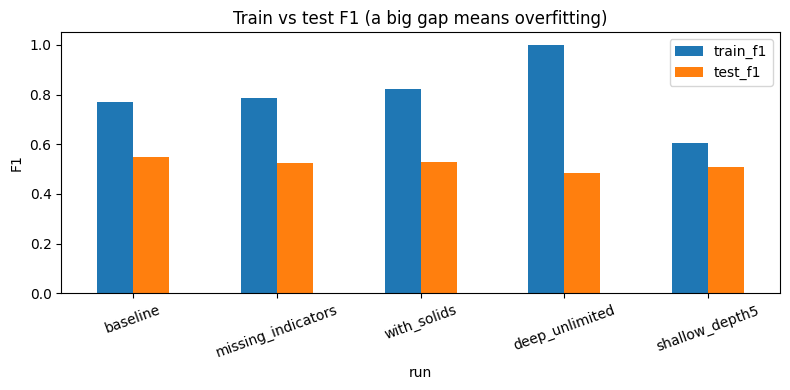

Best eligible run by validation F1: baseline (46a9c10098974b248a9d7d2da471e068)


In [30]:
runs = mlflow.search_runs(experiment_names=[CONFIG["mlflow"]["experiment_name"]])
runs = runs[runs["run_id"].isin(TRAINED)]   # only runs from this notebook session

cols = {"tags.mlflow.runName": "run", "metrics.train_f1": "train_f1", "metrics.val_f1": "val_f1",
        "metrics.test_f1": "test_f1", "metrics.test_accuracy": "test_acc",
        "metrics.test_roc_auc": "test_auc", "metrics.overfit_gap_f1": "overfit_gap"}
comparison = (runs[["run_id", *cols]].rename(columns=cols)
              .sort_values("val_f1", ascending=False).reset_index(drop=True))
display(comparison.drop(columns="run_id").round(3))

ax = comparison.set_index("run")[["train_f1", "test_f1"]].plot.bar(figsize=(8, 4), rot=20)
ax.set_ylabel("F1")
ax.set_title("Train vs test F1 (a big gap means overfitting)")
plt.tight_layout()
plt.show()

# Runs left out when choosing the model to deploy. with_solids is excluded because the
# solids column contradicts conductivity (Section 4b), so a real TDS-pen reading would
# fall far outside its training range. Set EXCLUDE_FROM_SELECTION = [] to allow it.
EXCLUDE_FROM_SELECTION = ["with_solids"]

eligible = comparison[~comparison["run"].isin(EXCLUDE_FROM_SELECTION)].reset_index(drop=True)
best_run_id = eligible.loc[0, "run_id"]
best_cfg, best_pipe, (X_test_best, y_test_best) = TRAINED[best_run_id]
print(f"Best eligible run by validation F1: {eligible.loc[0, 'run']} ({best_run_id})")

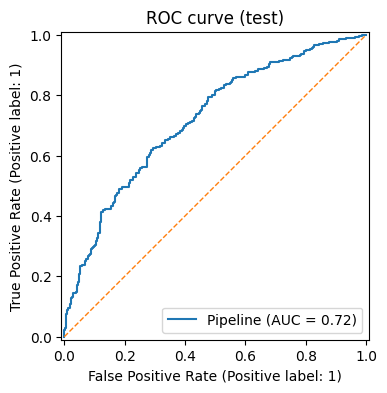

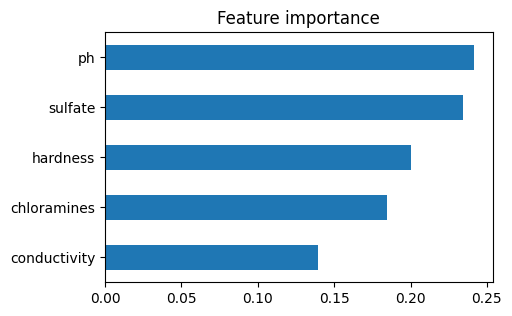

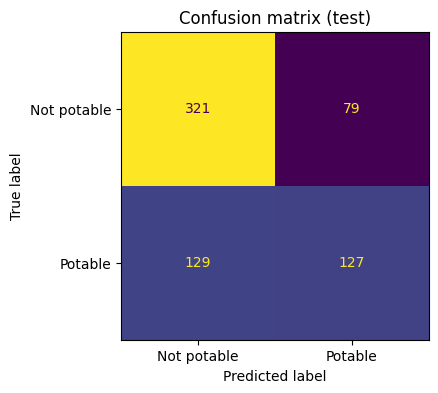

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

              precision    recall  f1-score   support

 not potable       0.71      0.80      0.76       400
     potable       0.62      0.50      0.55       256

    accuracy                           0.68       656
   macro avg       0.66      0.65      0.65       656
weighted avg       0.68      0.68      0.68       656



In [31]:
figs, importances = make_plots(best_pipe, X_test_best, y_test_best)
for fig in figs.values():
    plt.figure(fig.number)
    plt.show()

print(classification_report(y_test_best, best_pipe.predict(X_test_best),
                            target_names=["not potable", "potable"]))

In [32]:
os.makedirs("models", exist_ok=True)
joblib.dump(best_pipe, "models/model.joblib")

features = best_cfg["data"]["features"]
best_row = runs.set_index("run_id").loc[best_run_id]
model_info = {
    "mlflow_run_id": best_run_id,
    "run_name": best_row["tags.mlflow.runName"],
    "seed": SEED,
    "features": features,
    "target": best_cfg["data"]["target"],
    "metrics": {k.removeprefix("metrics."): round(float(v), 4)
                for k, v in best_row.items() if k.startswith("metrics.")},
    "training_ranges": {c: {"min": round(float(df[c].min()), 3),
                            "max": round(float(df[c].max()), 3),
                            "median": round(float(df[c].median()), 3)} for c in features},
    "feature_importance": importances.round(4).to_dict(),
}
with open("models/model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

with open("config.yaml", "w") as f:
    yaml.safe_dump(best_cfg, f, sort_keys=False)

print(json.dumps(model_info, indent=2))

{
  "mlflow_run_id": "46a9c10098974b248a9d7d2da471e068",
  "run_name": "baseline",
  "seed": 510,
  "features": [
    "ph",
    "hardness",
    "chloramines",
    "sulfate",
    "conductivity"
  ],
  "target": "potability",
  "metrics": {
    "val_precision": 0.5981,
    "train_precision": 0.8474,
    "train_accuracy": 0.8364,
    "train_roc_auc": 0.9214,
    "test_accuracy": 0.6829,
    "train_f1": 0.7715,
    "test_precision": 0.6165,
    "val_recall": 0.5,
    "test_f1": 0.5498,
    "val_f1": 0.5447,
    "test_roc_auc": 0.718,
    "test_recall": 0.4961,
    "train_recall": 0.7081,
    "val_roc_auc": 0.677,
    "val_accuracy": 0.6738,
    "overfit_gap_f1": 0.2217
  },
  "training_ranges": {
    "ph": {
      "min": 0.227,
      "max": 14.0,
      "median": 7.037
    },
    "hardness": {
      "min": 47.432,
      "max": 323.124,
      "median": 196.968
    },
    "chloramines": {
      "min": 0.352,
      "max": 13.127,
      "median": 7.13
    },
    "sulfate": {
      "min": 129.0,

In [33]:
sample = {"ph": 7.4, "hardness": 120, "solids": 250, "chloramines": 2.0,
          "sulfate": None, "conductivity": 400}
sample = {k: (np.nan if v is None else v) for k, v in sample.items() if k in features}

X_new = pd.DataFrame([sample], columns=features)
proba = best_pipe.predict_proba(X_new)[0, 1]
print(f"Probability potable: {proba:.1%}")

for col, value in sample.items():
    r = model_info["training_ranges"][col]
    if pd.isna(value):
        print(f"  {col}: missing, filled with the training median")
    elif not r["min"] <= value <= r["max"]:
        print(f"  WARNING {col}={value} is outside the training range {r['min']} to {r['max']}")

Probability potable: 55.8%
  sulfate: missing, filled with the training median


## 12. Download results
Downloads the model files plus the MLflow database and artifacts. To browse the full MLflow dashboard on your own computer, unzip, then run:

```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```
and open http://127.0.0.1:5000

In [34]:
!zip -qr mlflow_results.zip mlflow.db mlruns models config.yaml water_potability_clean.csv
try:
    from google.colab import files
    files.download("mlflow_results.zip")
except ImportError:
    print("Not in Colab: mlflow_results.zip is in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>